# NV2 — EDA và tiền xử lý dữ liệu UWB-FallTrack

Notebook này khám phá gói dữ liệu chính thức `abc2027_uwb_train_v1` và giải thích các bước tiền xử lý mà baseline dùng.
Báo cáo đầy đủ: [`reports/eda_preprocessing_report.md`](../reports/eda_preprocessing_report.md).

Nguyên tắc:

- Thống kê mô tả (số luồng, số cú ngã, thời lượng) dùng cả **train** và **val**.
- Phân tích tín hiệu và đặc trưng chỉ dùng **train**, để tập val không ảnh hưởng tới lựa chọn mô hình.
- Không đọc thư mục `segments/` (bản ghi nguồn LIARA), vì README của gói cấm dùng chúng để train hoặc suy luận.

Dữ liệu cần có tại `data/uwb_falltrack/abc2027_uwb_train_v1/`. Nếu chưa có, ô thứ ba sẽ chạy `python scripts/fetch_data.py --subset all` (tải khoảng 4,6 GB).

In [1]:
# Chạy được cả trên Colab lẫn máy cá nhân.
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/ank-less/ABC-UWB-Falltrack.git"
BRANCH = "sangkhoi"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("ABC-UWB-Falltrack").exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL], check=True)
    os.chdir("ABC-UWB-Falltrack")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[analysis,test]"], check=True)
else:
    # notebook nằm trong notebooks/: chuyển về thư mục gốc của repo
    root = Path.cwd()
    while not (root / "pyproject.toml").exists() and root != root.parent:
        root = root.parent
    os.chdir(root)
if str(Path.cwd() / "src") not in sys.path:
    sys.path.insert(0, str(Path.cwd() / "src"))
print("working directory:", Path.cwd())

working directory: D:\ABC-UWB-Falltrack


In [2]:
import json
import pandas as pd
from IPython.display import Image, display

from abc_uwb_falltrack import eda
from abc_uwb_falltrack.config import load_config, get
from abc_uwb_falltrack.manifest import build_manifest

if not Path("data/uwb_falltrack/abc2027_uwb_train_v1/streams/train").exists():
    subprocess.run([sys.executable, "scripts/fetch_data.py", "--subset", "all"], check=True)

cfg = load_config("configs/baseline.yaml")
FIG = Path("outputs/eda")          # hình sinh trong notebook (không commit)
manifest, segments, events = build_manifest(cfg)
pd.set_option("display.width", 160)
eda.overview_table(manifest, events, segments)

,split,streams,hours,falls,falls_per_hour,flagged_falls,fall_time_pct,adl_hours,fall_segment_hours,other_hours,subject_groups
0,train,13,6.18,359,58.1,173,2.95,4.49,1.22,0.57,12
1,val,5,2.05,119,58.1,52,3.35,1.47,0.42,0.19,4


## 1. Schema dữ liệu (đã xác nhận trên file thật)

Mỗi file `streams/<split>/stream_XX.h5` có:

- `cir`: shape `(3, T, 368)`, kiểu float32 (số thực), được chia chunk theo khối `(3, 5000, 368)`;
- `t`: thời gian tính bằng giây, bắt đầu từ 0, bước 0,02 s (50 Hz);
- `radar_serials`: serial của ba radar, `[29171, 29444, 30722]`.

Trục 1 của `cir` là trục thời gian, trục 2 là range bin.

In [3]:
first = manifest.iloc[0]
print(first[["stream_id", "n_radars", "n_frames", "n_bins", "dtype", "rate_hz", "dt_min", "dt_max", "timestamps_monotonic", "radar_serials"]].to_string())
manifest[["stream_id", "official_split", "duration_s", "n_events", "n_events_flagged", "n_segments", "n_subject_groups"]]

stream_id                        train_00
n_radars                                3
n_frames                            88117
n_bins                                368
dtype                             float32
rate_hz                              50.0
dt_min                               0.02
dt_max                               0.02
timestamps_monotonic                 True
radar_serials           29171;29444;30722


,stream_id,official_split,duration_s,n_events,n_events_flagged,n_segments,n_subject_groups
0,train_00,train,1762.34,30,15,145,12
1,train_01,train,1762.94,29,12,143,12
2,train_02,train,1718.46,25,8,142,12
3,train_03,train,1761.70,29,12,126,12
4,train_04,train,1764.86,26,10,137,12
5,train_05,train,1766.54,34,21,153,12
6,train_06,train,1767.12,27,13,138,12
7,train_07,train,1766.22,25,13,132,12
8,train_08,train,1767.42,27,12,137,12
9,train_09,train,1762.06,23,8,129,12


## 2. Nhãn: các cú ngã

Mỗi cú ngã là một khoảng `[t_start, t_end]`, tính từ lúc bắt đầu chuyển động tới lúc người đã nằm yên trên sàn. Cú ngã rất ngắn: trung vị khoảng 1,7 s.

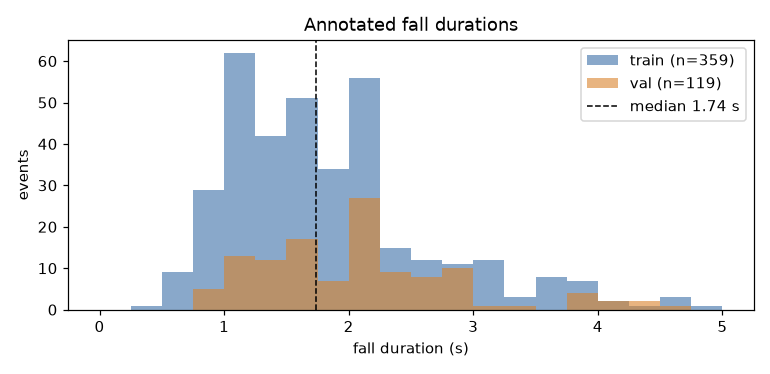

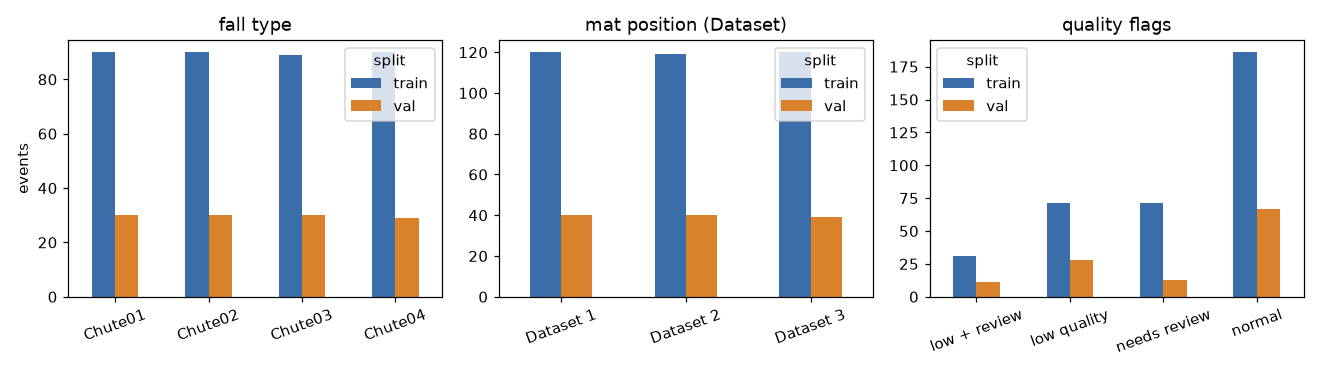

count    478.00
mean       1.89
std        0.83
min        0.48
10%        1.03
50%        1.74
90%        2.99
max        5.00
dtype: float64

In [4]:
display(Image(eda.fig_event_durations(events, FIG / "eda_fall_durations.png")))
display(Image(eda.fig_event_categories(events, FIG / "eda_fall_categories.png")))
(events["t_end"] - events["t_start"]).describe(percentiles=[0.1, 0.5, 0.9]).round(2)

## 3. Các luồng được ghép từ những bản ghi nguồn nào

`streams_composition.csv` cho biết mỗi luồng gồm những đoạn nguồn nào: ADL, ngã, hoặc "other" (phòng trống, các bản ghi khác).
Một file ADL nguồn được dùng lại trong nhiều luồng train, nên **chia fold theo luồng sẽ rò rỉ dữ liệu cùng người** giữa các fold.

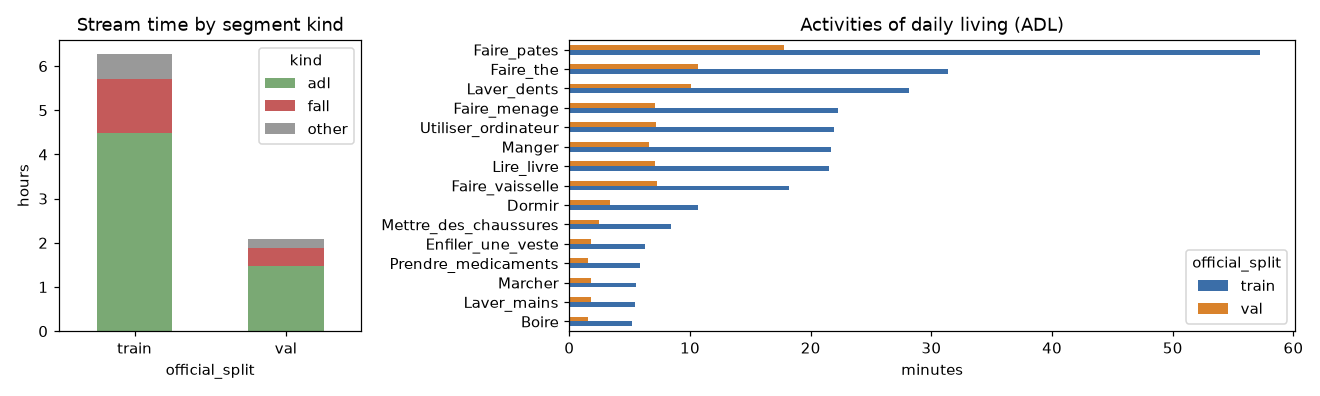

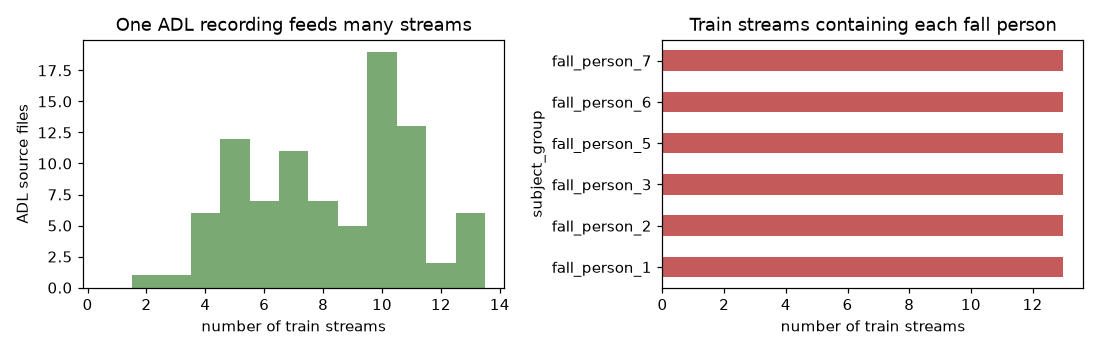

official_split
train    [adl_subject_10, adl_subject_12, adl_subject_4...
val      [adl_subject_0, adl_subject_11, fall_person_8,...
Name: subject_group, dtype: object

In [5]:
display(Image(eda.fig_composition(segments, FIG / "eda_composition.png")))
display(Image(eda.fig_source_reuse(segments, FIG / "eda_source_reuse.png")))
segments.groupby("official_split")["subject_group"].agg(lambda s: sorted(set(s)))

## 4. Tín hiệu quanh một cú ngã và tác dụng của việc trừ nền

Ở CIR thô, phần phản xạ tĩnh (tường, đồ đạc) chiếm ưu thế. Bộ lọc EMA nhân quả với hằng số thời gian `tau = 3 s` (giống ý tưởng baseline chính thức) loại bỏ phần tĩnh, chỉ giữ lại chuyển động.

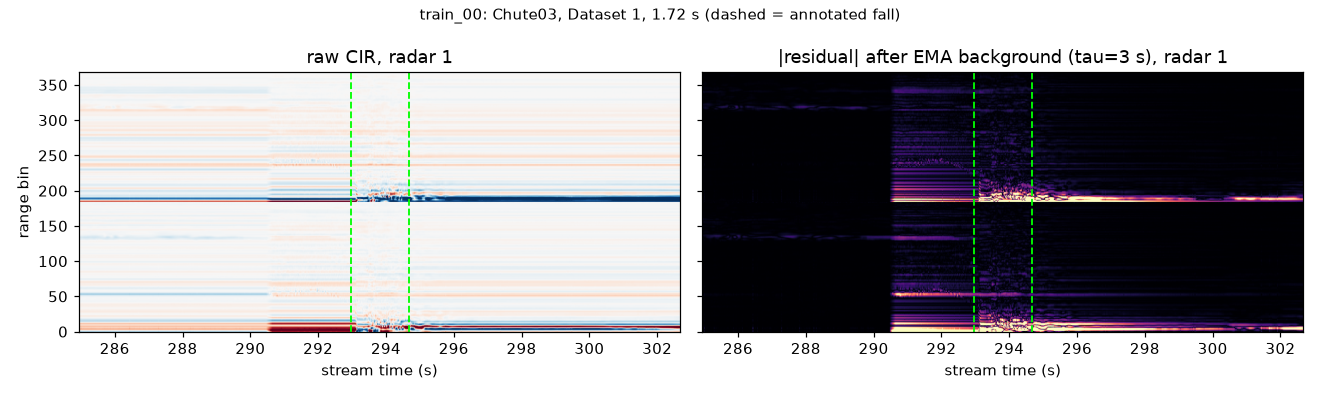

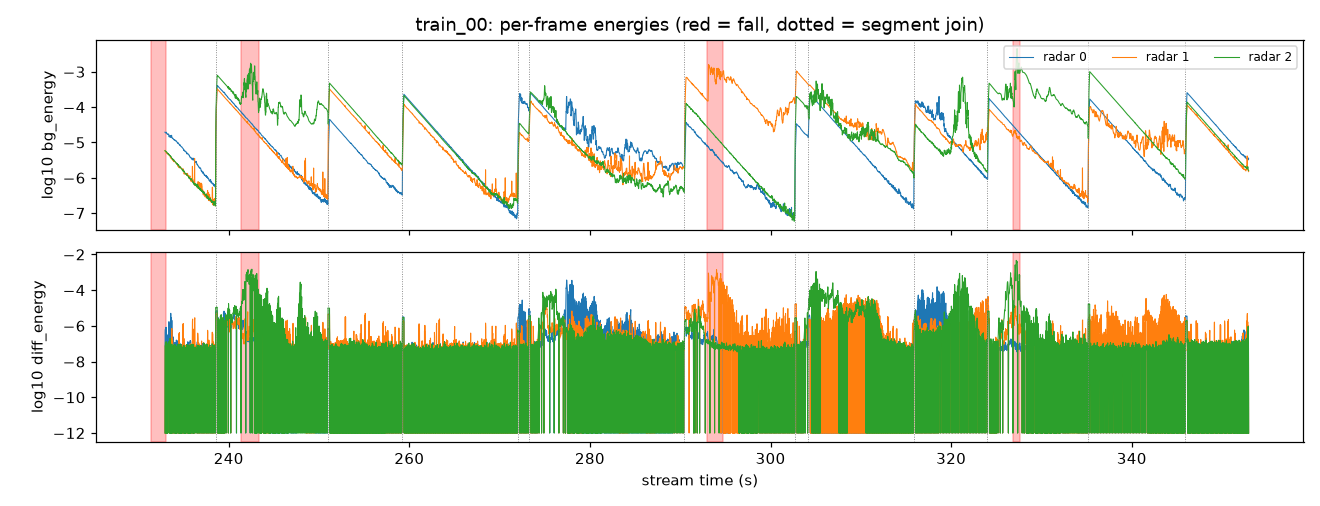

In [6]:
from abc_uwb_falltrack.preprocessing import cached_frame_series

rate = float(get(cfg, "data.rate_hz"))
row = manifest[manifest["stream_id"] == "train_00"].iloc[0]
ev = events[(events["stream_id"] == "train_00") & ~events["flagged"]]
example = ev.iloc[(ev["t_end"] - ev["t_start"] - 1.74).abs().argsort().iloc[0]]
display(Image(eda.fig_range_time(row, example, rate, 3.0, FIG / "eda_range_time_fall.png")))

values, valid, _ = cached_frame_series(Path(row.file_path), rate, 3.0, 5000, int(row.n_frames), ("bg_energy", "diff_energy"), Path("outputs/cache/frame_series"))
t0 = max(0.0, float(example.t_start) - 60)
display(Image(eda.fig_energy_timeline(values, rate, events, segments, "train_00", t0, t0 + 120, FIG / "eda_energy_timeline.png")))

## 5. Chọn độ dài cửa sổ

Metric chính thức dựa trên tIoU giữa khoảng dự đoán và khoảng thật. Cửa sổ dài hơn nhiều so với một cú ngã (khoảng 1,7 s) thì tIoU tối đa sẽ thấp.
Bảng dưới đếm cửa sổ dương, âm và mơ hồ trên tập train với stride 0,2 s.

In [7]:
eda.window_label_sensitivity(manifest, events, cfg)

,window_s,positive,negative,ambiguous,positive_pct,falls_with_a_positive_window_pct,single_window_event_tiou_at_median_fall
0,0.5,3275,107121,852,2.94,100.0,0.29
1,1.0,3337,106170,1709,3.00,100.0,0.57
2,2.0,4043,104310,2798,3.64,100.0,0.87
3,4.0,7192,100614,3215,6.48,100.0,0.44


## 6. Đặc trưng nào tách được cửa sổ ngã và không ngã (chỉ trên train)

Đặc trưng được tính từ chuỗi năng lượng theo từng frame (sau khi trừ nền) và năng lượng sai phân giữa hai frame liên tiếp, gom theo cửa sổ 1 s. Cột AUC là khả năng tách lớp của từng đặc trưng khi dùng riêng lẻ.

label
negative     106170
positive       3328
ambiguous      1718
Name: count, dtype: int64


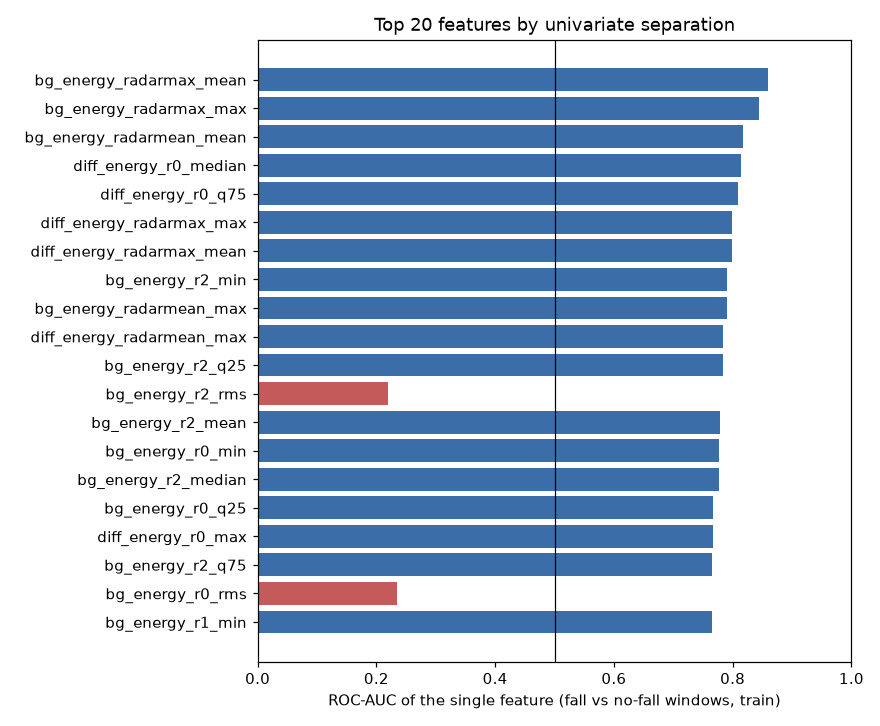

,feature,auc,separation
0,bg_energy_radarmax_mean,0.858819,0.358819
1,bg_energy_radarmax_max,0.844109,0.344109
2,bg_energy_radarmean_mean,0.816856,0.316856
3,diff_energy_r0_median,0.814743,0.314743
4,diff_energy_r0_q75,0.809264,0.309264
5,diff_energy_radarmax_max,0.798725,0.298725
6,diff_energy_radarmax_mean,0.798116,0.298116
7,bg_energy_r2_min,0.790258,0.290258
8,bg_energy_radarmean_max,0.790102,0.290102
9,diff_energy_radarmean_max,0.783835,0.283835


In [8]:
windows, matrix, names = eda.train_windows(cfg, manifest, events)
print(windows["label"].value_counts().rename({1: "positive", 0: "negative", -1: "ambiguous"}))
auc = eda.univariate_auc(matrix, windows["label"].to_numpy(), names)
display(Image(eda.fig_feature_auc(auc, FIG / "eda_feature_auc.png")))
auc.head(10)

## 7. Kiểm tra các "đường tắt" có thể có trong dữ liệu

- **Chỗ nối giữa các đoạn ghép**: ở chỗ nối có crossfade 0,2 s. Nếu chỗ nối trông giống một cú ngã, mô hình có thể học nhầm dấu hiệu nhân tạo này.
- **Vị trí**: cú ngã được ghi ở ba vị trí thảm cố định, còn ADL được ghi ở chỗ khác trong căn hộ. Đặc trưng vị trí (range centroid) có thể tách lớp mà không cần hiểu gì về cú ngã.

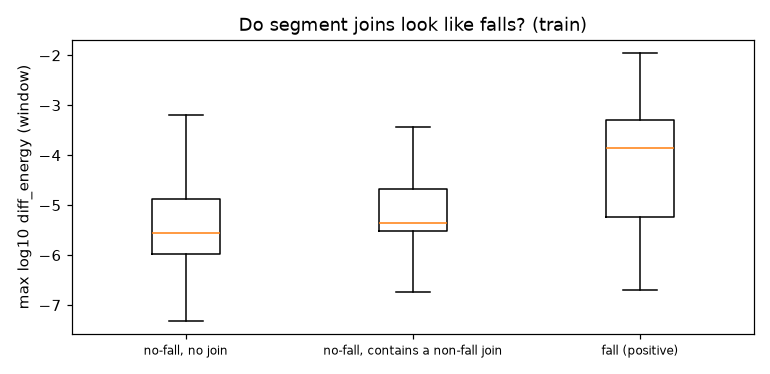

,group,windows,median,q90
0,"no-fall, no join",100730,-5.562937,-4.252549
1,"no-fall, contains a non-fall join",5440,-5.354439,-4.148666
2,fall (positive),3328,-3.851650,-2.982771


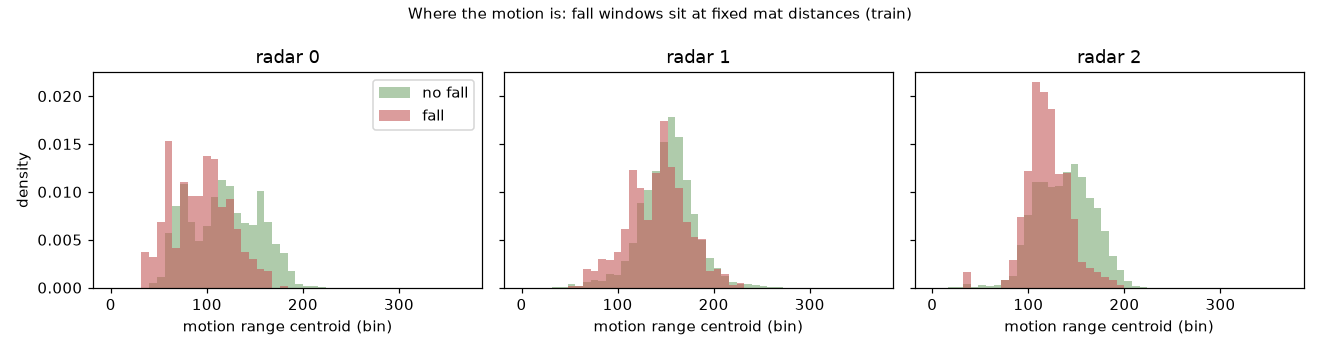

,radar,auc_fall_vs_nofall,median_bin_fall,median_bin_nofall
0,0,0.313214,94.878486,117.919760
1,1,0.397784,145.730131,153.657723
2,2,0.314934,117.812091,138.518745


In [9]:
table, samples = eda.junction_table(windows, matrix, names, segments)
display(Image(eda.fig_junction(samples, FIG / "eda_junctions.png")))
display(table)
location, location_samples = eda.location_table(cfg, manifest, events, ["train_00", "train_01", "train_02"])
display(Image(eda.fig_location(location_samples, FIG / "eda_location_cue.png")))
location

In [10]:
eda.tau_effect(cfg, manifest, events, ["train_00", "train_01", "train_02"])

,tau_s,feature,auc
0,1.0,bg_energy_radarmax_mean,0.823677
1,1.0,bg_energy_radarmax_max,0.816907
2,3.0,bg_energy_radarmax_mean,0.876060
3,3.0,bg_energy_radarmax_max,0.861499
4,8.0,bg_energy_radarmax_mean,0.899007
5,8.0,bg_energy_radarmax_max,0.889183


## 8. Kết luận cho tiền xử lý

1. Dùng các luồng chính thức ở 50 Hz, không cần nội suy: timestamp đều và không có NaN/Inf.
2. Trừ nền bằng EMA nhân quả với `tau = 3 s`, tính theo từng khúc của file. Bước này không fit trên dữ liệu nên không gây rò rỉ.
3. Mỗi frame chỉ tóm tắt thành năng lượng phần dư và năng lượng sai phân của từng radar. Không flatten tensor CIR.
4. Dùng cửa sổ 1 s, stride 0,2 s, gán nhãn theo tỉ lệ chồng lấn thời gian. Cửa sổ mơ hồ bị loại khỏi tập huấn luyện.
5. Cross-validation bên trong train chia theo người (`subject_group`), không chia theo luồng.
6. Mặc định không dùng đặc trưng vị trí, vì đó là đường tắt của bộ dữ liệu.